In [1]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt
import matplotlib
import json5 as json

import uproot

os.environ.get("ROOTSYS")

'/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311'

In [2]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

## Atown's stuff
sys.path.append("..")
from globalsC2 import *
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

import MakeSpectra as MS
print(COMP2PATH)

Welcome to JupyROOT 6.27/01
CF4HOME: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4
COMP2PATH: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2
/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2


---
### Cs - LP background runs

In [3]:
## loading run lists
rid_Cs_bkg = np.loadtxt(os.path.join(COMP2PATH, "runLists/CsLists/LPfilter_april_48V_background.txt"), dtype=str).tolist()
print(f"Loaded {len(rid_Cs_bkg)} runs for Cs background.")

runId, speValues, rc_Cs_LP_bkg, tFiles = MS.ExtractSPE(fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"), argRunList=rid_Cs_bkg)

Loaded 7 runs for Cs background.


2025-12-10 00:03:35.955 Python[14062:86824347] WARNING: Secure coding is not enabled for restorable state! Enable secure coding by implementing NSApplicationDelegate.applicationSupportsSecureRestorableState: and returning YES.


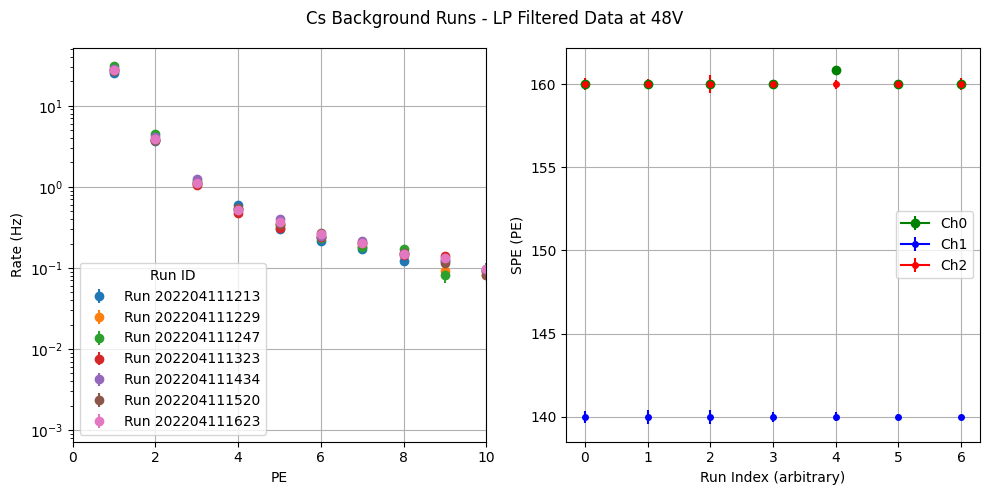

In [4]:
## plotting SPE vs background run
fig, (axbkg, axspe) = plt.subplots(1, 2, figsize=(10, 5))

anaCfg = MS.AnalysisConfig(os.path.join(COMP2PATH, "pyScripts/analysis.json"))

chCols = ["green", "blue", "red"]
for i, rc in enumerate(rc_Cs_LP_bkg):
  rc.mpl_errorbar(axbkg, rate = True, label=f"Run {rc.id}", fmt='o', color=f"C{i}") 
  
  for ich in range(anaCfg.nChan):
    chan = rc.GetChan(ich)
    label = None
    if i == 0:
      label = f"Ch{ich}"
    msize = 6 if ich == 0 else 4
    axspe.errorbar(i, chan.mSpe.spe, yerr=chan.mSpe.espe, marker = "o", markersize=msize, color=chCols[ich], label=label)

axbkg.set_xlim(0, 10)
axbkg.set_yscale('log')

# axbkg.vlines((1, 2), ymin=1e-4, ymax=1e2, colors='gray', linestyles='dashed')

axbkg.legend(title="Run ID")
axbkg.set_xlabel("PE")
axbkg.set_ylabel("Rate (Hz)")
axbkg.grid()

axspe.legend()
axspe.set_ylabel("SPE (PE)")
axspe.set_xlabel("Run Index (arbitrary)")

axspe.grid()

fig.suptitle("Cs Background Runs - LP Filtered Data at 48V")
plt.tight_layout()
plt.show()

---
### Co - LP background runs

In [5]:
## loading run lists
rid_Co_bkg = np.loadtxt(os.path.join(COMP2PATH, "runLists/CoLists/LPfilter_april_48V_fineCol_bkg.txt"), dtype=str).tolist()
print(f"Loaded {len(rid_Co_bkg)} runs for Co background.")

runId, speValues, rc_Co_LP_bkg, tFiles = MS.ExtractSPE(fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"), argRunList=rid_Co_bkg)

Loaded 7 runs for Co background.


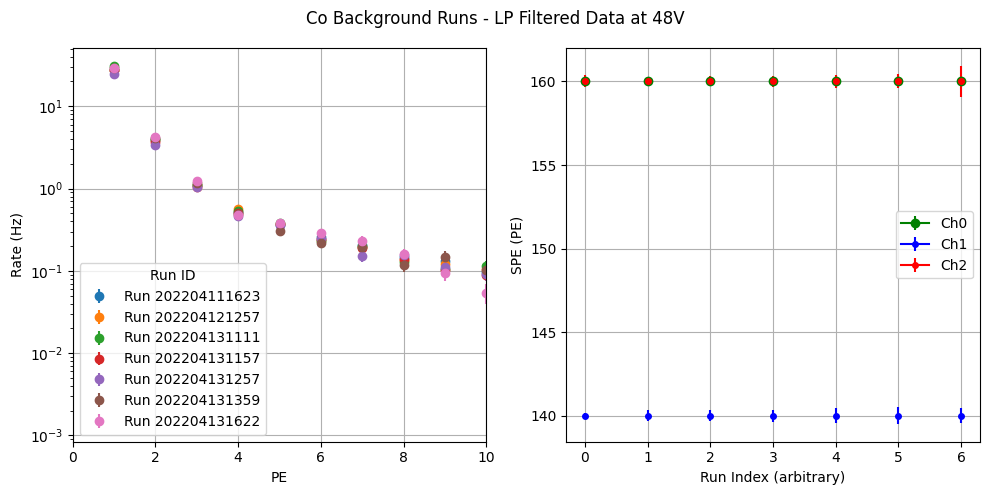

In [6]:
## plotting SPE vs background run
fig, (axbkg, axspe) = plt.subplots(1, 2, figsize=(10, 5))

anaCfg = MS.AnalysisConfig(os.path.join(COMP2PATH, "pyScripts/analysis.json"))

chCols = ["green", "blue", "red"]
for i, rc in enumerate(rc_Co_LP_bkg):
  rc.mpl_errorbar(axbkg, rate = True, label=f"Run {rc.id}", fmt='o', color=f"C{i}")
  
  for ich in range(anaCfg.nChan):
    chan = rc.GetChan(ich)
    label = None
    if i == 0:
      label = f"Ch{ich}"
    msize = 6 if ich == 0 else 4
    axspe.errorbar(i, chan.mSpe.spe, yerr=chan.mSpe.espe, marker = "o", markersize=msize, color=chCols[ich], label=label)

axbkg.set_xlim(0, 10)
axbkg.set_yscale('log')

# axbkg.vlines((1, 2), ymin=1e-4, ymax=1e2, colors='gray', linestyles='dashed')

axbkg.legend(title="Run ID")
axbkg.set_xlabel("PE")
axbkg.set_ylabel("Rate (Hz)")
axbkg.grid()

axspe.legend()
axspe.set_ylabel("SPE (PE)")
axspe.set_xlabel("Run Index (arbitrary)")

axspe.grid()

fig.suptitle("Co Background Runs - LP Filtered Data at 48V")
plt.tight_layout()
plt.show()

---
### Averaging backgrounds

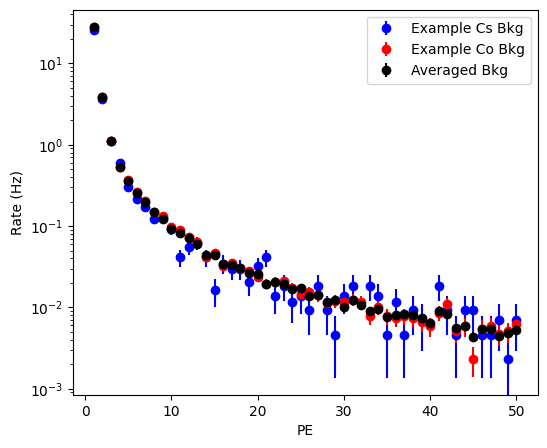

In [7]:
## can do this manually, or call MakeSpectra.buildhistogram()

## lets add up (average) all the background runs from both Co and Cs
# rcAvgBkg = RunClass.copy_rc_empty(name="Averaged Bkg", rcIn=rc_Cs_LP_bkg[0])
# rcAvgBkg.AverageRCs(rcList=rc_Cs_LP_bkg + rc_Co_LP_bkg)
rcAvgBkg = RunClass.CombineRCs(name="avg_bkp_lp", rcList=rc_Cs_LP_bkg + rc_Co_LP_bkg)

fig, axAvg = plt.subplots(1, 1, figsize=(6, 5))

rc_Cs_LP_bkg[0].mpl_errorbar(axAvg, rate = True, label="Example Cs Bkg", fmt='o', color='blue')
rc_Co_LP_bkg[0].mpl_errorbar(axAvg, rate = True, label="Example Co Bkg", fmt='o', color='red')
rcAvgBkg.mpl_errorbar(axAvg, rate = True, label="Averaged Bkg", fmt='o', color='black')

axAvg.set_yscale('log')
axAvg.set_xlabel("PE")
axAvg.set_ylabel("Rate (Hz)")
axAvg.legend()

---
### Signal analysis

In [9]:
## loading run lists
rid_Co, heights_Co = np.loadtxt(os.path.join(COMP2PATH, "runLists/CoLists/LPfilter_april_48V_fineCol.txt"), dtype=str, delimiter=",", unpack=True)

runId, speValues, rc_Co_LP_bkg, tFiles = MS.ExtractSPE(argRunList=rid_Co, fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"))

for rc, h in zip(rc_Co_LP_bkg, heights_Co):
  rc.mHeight = float(h)
  rc.print()
# print(f"Loaded {len(rid_Co_bkg)} runs for Co background.")


runID: 202204131513
Nevents: 167817.00,   time: 68.29 min
average Rate: 40.96 Hz
height = 26.00
chID:0: spe = 160.00 +/- 0.07     maxChi2 = 0.00
chID:1: spe = 140.00 +/- 0.11     maxChi2 = 0.00
chID:2: spe = 160.00 +/- 0.18     maxChi2 = 0.00

runID: 202204131317
Nevents: 111250.00,   time: 41.72 min
average Rate: 44.44 Hz
height = 28.50
chID:0: spe = 160.00 +/- 0.10     maxChi2 = 0.00
chID:1: spe = 140.02 +/- 0.13     maxChi2 = 0.00
chID:2: spe = 160.00 +/- 0.30     maxChi2 = 0.00

runID: 202204131122
Nevents: 130985.00,   time: 34.32 min
average Rate: 63.60 Hz
height = 30.50
chID:0: spe = 160.00 +/- 0.06     maxChi2 = 0.00
chID:1: spe = 140.00 +/- 0.09     maxChi2 = 0.00
chID:2: spe = 160.00 +/- 0.06     maxChi2 = 0.00


In [ ]:
## okay. we will scale the average backgrounds by the run time for the given data.

# then do the subtraction as 'expected'.

Nsignal = Ndata - R_bkg x time

sigmaBkg = sqrt((time x sigmaR_bkg)^2 + R_bkg x time)
error_signal = sqrt( Ndata + sigmaBkg^2 )